# 🔬 Exploration des données HADACA

Ce notebook va nous permettre de comprendre la structure des données avant de développer notre algorithme de déconvolution.

## Objectif
Estimer les **proportions de types cellulaires** dans des mélanges biologiques.

## 1. Import des bibliothèques

In [1]:
import pandas as pd
import numpy as np
import h5py
import os

# Chemin vers les données
DATA_PATH = "data/"
GROUND_TRUTH_PATH = "ground_truth/"

print("✅ Bibliothèques importées avec succès!")

✅ Bibliothèques importées avec succès!


## 2. Lister les fichiers disponibles

In [2]:
# Fichiers de mélanges (à déconvoluer)
print("📁 Fichiers de MÉLANGES:")
for f in sorted(os.listdir(DATA_PATH)):
    print(f"  - {f}")

print("\n📁 Fichiers GROUND TRUTH (proportions réelles):")
for f in sorted(os.listdir(GROUND_TRUTH_PATH)):
    print(f"  - {f}")

📁 Fichiers de MÉLANGES:
  - mixes_SBN5.h5
  - mixes_SDC5.h5
  - mixes_SDE5.h5
  - mixes_SDEL.h5
  - mixes_SDN4.h5
  - mixes_SDN5.h5
  - mixes_SDN6.h5
  - mixes_VITR.h5
  - mixes_VIVO.h5
  - reference_pdac.h5

📁 Fichiers GROUND TRUTH (proportions réelles):
  - groundtruth_SBN5.h5
  - groundtruth_SDC5.h5
  - groundtruth_SDE5.h5
  - groundtruth_SDEL.h5
  - groundtruth_SDN4.h5
  - groundtruth_SDN5.h5
  - groundtruth_SDN6.h5
  - groundtruth_VITR.h5
  - groundtruth_VIVO.h5


## 3. Explorer la structure d'un fichier HDF5

Les fichiers `.h5` (HDF5) sont des fichiers hiérarchiques qui peuvent contenir plusieurs datasets.

In [3]:
# Fonction pour explorer la structure d'un fichier HDF5
def explore_h5(filepath):
    """Affiche la structure hiérarchique d'un fichier HDF5"""
    def print_structure(name, obj):
        indent = "  " * name.count("/")
        if isinstance(obj, h5py.Dataset):
            print(f"{indent}📊 {name}: shape={obj.shape}, dtype={obj.dtype}")
        else:
            print(f"{indent}📁 {name}/")
    
    with h5py.File(filepath, 'r') as f:
        print(f"\n🔍 Structure de: {filepath}")
        print("-" * 50)
        f.visititems(print_structure)

# Explorer un fichier de mélange
explore_h5(DATA_PATH + "mixes_SDN5.h5")


🔍 Structure de: data/mixes_SDN5.h5
--------------------------------------------------
📁 mix_met/
  📊 mix_met/CpG_sites: shape=(23724,), dtype=|S10
  📊 mix_met/data: shape=(30, 23724), dtype=float64
📁 mix_rna/
  📊 mix_rna/data: shape=(30, 15908), dtype=float64
  📊 mix_rna/genes: shape=(15908,), dtype=|S13


In [4]:
# Explorer le fichier de référence
explore_h5(DATA_PATH + "reference_pdac.h5")


🔍 Structure de: data/reference_pdac.h5
--------------------------------------------------
📁 ref_bulkRNA/
  📊 ref_bulkRNA/cell_types: shape=(5,), dtype=|S7
  📊 ref_bulkRNA/data: shape=(5, 15908), dtype=float64
  📊 ref_bulkRNA/genes: shape=(15908,), dtype=|S13
📁 ref_met/
  📊 ref_met/CpG_sites: shape=(23724,), dtype=|S10
  📊 ref_met/cell_types: shape=(5,), dtype=|S7
  📊 ref_met/data: shape=(5, 23724), dtype=float64
📁 ref_scRNA/
  📁 ref_scRNA/ref_sc_baron/
    📊 ref_scRNA/ref_sc_baron/cell: shape=(551,), dtype=|S48
    📊 ref_scRNA/ref_sc_baron/data: shape=(982828,), dtype=int32
    📊 ref_scRNA/ref_sc_baron/genes: shape=(20125,), dtype=|S22
    📊 ref_scRNA/ref_sc_baron/indices: shape=(982828,), dtype=int32
    📊 ref_scRNA/ref_sc_baron/indptr: shape=(552,), dtype=int32
    📊 ref_scRNA/ref_sc_baron/meta: shape=(551,), dtype=[('cell_type', '<i4'), ('sample', 'S3')]
    📊 ref_scRNA/ref_sc_baron/shape: shape=(2,), dtype=int32
  📁 ref_scRNA/ref_sc_peng/
    📊 ref_scRNA/ref_sc_peng/cell: shape=(4

In [5]:
# Explorer un fichier ground truth
explore_h5(GROUND_TRUTH_PATH + "groundtruth_SDN5.h5")


🔍 Structure de: ground_truth/groundtruth_SDN5.h5
--------------------------------------------------
📁 groundtruth/
  📊 groundtruth/data: shape=(30, 5), dtype=float64
  📊 groundtruth/genes: shape=(5,), dtype=|S7


## 4. Charger et afficher les données

Maintenant, chargeons les données pour voir concrètement leur contenu.

In [6]:
# Charger un fichier de mélange (données RNA)
with h5py.File(DATA_PATH + "mixes_SDN5.h5", 'r') as f:
    # Lire les données RNA
    mix_data = f['mix_rna/data'][:]
    mix_genes = [x.decode('utf-8') for x in f['mix_rna/genes'][:]]

# Créer un DataFrame (les lignes = gènes, les colonnes = échantillons)
mix_df = pd.DataFrame(mix_data, columns=mix_genes).T
mix_df.columns = [f"sample_{i+1}" for i in range(mix_df.shape[1])]

print(f"📊 Dimensions du mélange RNA: {mix_df.shape}")
print(f"   - {mix_df.shape[0]} gènes (features)")
print(f"   - {mix_df.shape[1]} échantillons (samples)")
print("\n🔍 Aperçu des données:")
mix_df.head()

📊 Dimensions du mélange RNA: (15908, 30)
   - 15908 gènes (features)
   - 30 échantillons (samples)

🔍 Aperçu des données:


,sample_1,sample_2,sample_3,sample_4,sample_5,sample_6,sample_7,sample_8,sample_9,sample_10,...,sample_21,sample_22,sample_23,sample_24,sample_25,sample_26,sample_27,sample_28,sample_29,sample_30
A1BG,222.222060,236.501245,208.033562,276.948361,221.612633,184.742675,162.651030,236.670357,232.247751,226.012861,...,170.592550,208.772405,189.442578,186.097293,242.196050,205.858428,191.737684,175.233281,182.331706,169.365004
A1BG-AS1,257.725577,275.359791,233.896681,314.488948,256.860005,221.191808,188.119925,276.479847,273.854996,266.480084,...,198.879774,241.135191,219.928144,215.740743,268.512307,237.375151,231.301629,202.827920,214.022132,191.921646
A1CF,5.999562,4.137792,5.460566,2.157423,7.820163,7.198666,2.645498,5.502356,3.448705,0.731393,...,6.811081,5.454018,7.404591,4.370621,4.800603,5.057639,4.350739,6.996023,4.608417,3.861011
A2M,1297.704993,1391.966391,1596.961116,2208.209580,2006.231674,1111.386204,1080.051663,1585.645435,1549.231856,1415.098212,...,1470.302793,1001.400912,1206.568889,1158.688216,1924.154273,1242.489784,1300.572038,1143.660295,1046.545839,1167.342172
A2M-AS1,15.786761,21.532031,18.576861,17.866846,14.089702,13.583833,9.737718,14.976610,14.170936,14.371088,...,13.937492,14.933446,14.282139,10.824611,16.183721,14.241131,12.336445,12.267211,11.485355,10.676374


In [7]:
# Charger le fichier de référence (profils des types cellulaires)
with h5py.File(DATA_PATH + "reference_pdac.h5", 'r') as f:
    ref_data = f['ref_bulkRNA/data'][:]
    ref_cell_types = [x.decode('utf-8') for x in f['ref_bulkRNA/cell_types'][:]]
    ref_genes = [x.decode('utf-8') for x in f['ref_bulkRNA/genes'][:]]

# Créer un DataFrame
ref_df = pd.DataFrame(ref_data.T, index=ref_genes, columns=ref_cell_types)

print(f"📊 Dimensions de la référence: {ref_df.shape}")
print(f"   - {ref_df.shape[0]} gènes (features)")
print(f"   - {ref_df.shape[1]} types cellulaires")
print(f"\n🧬 Types cellulaires disponibles:")
for ct in ref_cell_types:
    print(f"   - {ct}")
print("\n🔍 Aperçu des données:")
ref_df.head()

📊 Dimensions de la référence: (15908, 5)
   - 15908 gènes (features)
   - 5 types cellulaires

🧬 Types cellulaires disponibles:
   - endo
   - fibro
   - immune
   - classic
   - basal

🔍 Aperçu des données:


,endo,fibro,immune,classic,basal
A1BG,0.106748,10.276785,6.194265,0.161687,0.085805
A1BG-AS1,1.191234,3.842044,2.889991,0.015596,0.000000
A1CF,0.000000,0.043855,0.033560,34.381641,0.524496
A2M,35.440235,17.270865,556.112949,0.202604,0.030284
A2M-AS1,0.853982,0.730762,3.881392,0.151279,0.337142


In [8]:
# Charger le ground truth (proportions réelles)
with h5py.File(GROUND_TRUTH_PATH + "groundtruth_SDN5.h5", 'r') as f:
    gt_data = f['groundtruth/data'][:]
    gt_cell_types = [x.decode('utf-8') for x in f['groundtruth/genes'][:]]

# Créer un DataFrame (lignes = types cellulaires, colonnes = échantillons)
gt_df = pd.DataFrame(gt_data, columns=gt_cell_types).T
gt_df.columns = [f"sample_{i+1}" for i in range(gt_df.shape[1])]

print(f"📊 Dimensions du ground truth: {gt_df.shape}")
print(f"   - {gt_df.shape[0]} types cellulaires")
print(f"   - {gt_df.shape[1]} échantillons")
print("\n🎯 Proportions réelles (ce qu'on doit prédire):")
gt_df

📊 Dimensions du ground truth: (5, 30)
   - 5 types cellulaires
   - 30 échantillons

🎯 Proportions réelles (ce qu'on doit prédire):


,sample_1,sample_2,sample_3,sample_4,sample_5,sample_6,sample_7,sample_8,sample_9,sample_10,...,sample_21,sample_22,sample_23,sample_24,sample_25,sample_26,sample_27,sample_28,sample_29,sample_30
endo,0.097580,0.128644,0.104060,0.099337,0.241164,0.296590,0.231888,0.163149,0.160960,0.235989,...,0.283930,0.152506,0.158723,0.227352,0.106995,0.142269,0.285233,0.182895,0.180729,0.068226
fibro,0.519555,0.551551,0.431835,0.582073,0.386463,0.380035,0.352930,0.520347,0.506521,0.501442,...,0.282206,0.498900,0.406483,0.410243,0.486409,0.464152,0.386871,0.367527,0.419826,0.398956
immune,0.095015,0.101319,0.125064,0.180726,0.178081,0.085723,0.048338,0.120176,0.117509,0.097062,...,0.130519,0.059465,0.096530,0.051834,0.157703,0.088902,0.097115,0.085959,0.057978,0.044448
classic,0.267101,0.190246,0.275827,0.091492,0.177587,0.219523,0.124286,0.147170,0.166887,0.074539,...,0.291630,0.228855,0.336922,0.064183,0.201261,0.257512,0.164270,0.320210,0.208947,0.185109
basal,0.020749,0.028240,0.063215,0.046372,0.016706,0.018129,0.242558,0.049157,0.048123,0.090968,...,0.011715,0.060273,0.001341,0.246388,0.047632,0.047165,0.066512,0.043409,0.132520,0.303260


In [9]:
# Vérifier que les proportions somment à 1
print("✅ Vérification : les proportions de chaque échantillon somment à 1?")
print(gt_df.sum(axis=0))

✅ Vérification : les proportions de chaque échantillon somment à 1?
sample_1     1.0
sample_2     1.0
sample_3     1.0
sample_4     1.0
sample_5     1.0
sample_6     1.0
sample_7     1.0
sample_8     1.0
sample_9     1.0
sample_10    1.0
sample_11    1.0
sample_12    1.0
sample_13    1.0
sample_14    1.0
sample_15    1.0
sample_16    1.0
sample_17    1.0
sample_18    1.0
sample_19    1.0
sample_20    1.0
sample_21    1.0
sample_22    1.0
sample_23    1.0
sample_24    1.0
sample_25    1.0
sample_26    1.0
sample_27    1.0
sample_28    1.0
sample_29    1.0
sample_30    1.0
dtype: float64


# STOOOOOOOOOP

## 6. 🔍 Exploration complète de TOUS les datasets

Explorons tous les fichiers de mélanges et leurs ground truths correspondants.

In [24]:
# Fonction utilitaire pour charger les données RNA (gère les 2 formats)
def load_mix_rna(filepath):
    """
    Charge les données RNA d'un fichier mixes_*.h5
    Gère les 2 formats: matrice 2D classique et structured array
    Retourne: DataFrame (gènes × échantillons)
    """
    with h5py.File(filepath, 'r') as f:
        data = f['mix_rna/data'][:]
        genes = [x.decode('utf-8') for x in f['mix_rna/genes'][:]]
        
        # Vérifier si c'est un structured array (VIVO, SBN5)
        if data.dtype.names is not None:
            # Format structured array: les colonnes sont les samples
            sample_names = list(data.dtype.names)
            # Convertir en DataFrame
            df = pd.DataFrame({name: data[name] for name in sample_names})
            df.index = genes
        else:
            # Format classique: matrice 2D (samples × genes)
            df = pd.DataFrame(data.T, index=genes)
            df.columns = [f"sample_{i+1}" for i in range(df.shape[1])]
    
    return df

# Liste de tous les datasets disponibles
datasets = ['SBN5', 'SDC5', 'SDE5', 'SDEL', 'SDN4', 'SDN5', 'SDN6', 'VITR', 'VIVO']

# Résumé de tous les mélanges
print("=" * 70)
print("📊 RÉSUMÉ DE TOUS LES DATASETS DE MÉLANGES")
print("=" * 70)

summary_data = []

for ds in datasets:
    mix_path = f"{DATA_PATH}mixes_{ds}.h5"
    gt_path = f"{GROUND_TRUTH_PATH}groundtruth_{ds}.h5"
    
    try:
        # Charger les données RNA avec notre fonction robuste
        mix_df_temp = load_mix_rna(mix_path)
        n_genes = mix_df_temp.shape[0]
        n_samples = mix_df_temp.shape[1]
        
        # Vérifier s'il y a des données de méthylation
        with h5py.File(mix_path, 'r') as f:
            has_met = 'mix_met' in f
        
        # Charger le ground truth
        with h5py.File(gt_path, 'r') as f:
            n_cell_types = f['groundtruth/data'].shape[1]
            cell_types = [x.decode('utf-8') for x in f['groundtruth/genes'][:]]
        
        summary_data.append({
            'Dataset': ds,
            'Échantillons': n_samples,
            'Gènes': n_genes,
            'Types cellulaires': n_cell_types,
            'Noms types': ', '.join(cell_types),
            'Méthylation': '✅' if has_met else '❌'
        })
        
        print(f"\n✅ {ds}:")
        print(f"   - Échantillons: {n_samples}")
        print(f"   - Gènes: {n_genes}")
        print(f"   - Types cellulaires: {n_cell_types} ({', '.join(cell_types)})")
        print(f"   - Méthylation: {'Oui' if has_met else 'Non'}")
        
    except Exception as e:
        print(f"\n⚠️ {ds}: Erreur - {e}")

# Créer un DataFrame résumé
summary_df = pd.DataFrame(summary_data)
print("\n" + "=" * 70)
print("📋 TABLEAU RÉCAPITULATIF")
print("=" * 70)
summary_df

📊 RÉSUMÉ DE TOUS LES DATASETS DE MÉLANGES

✅ SBN5:
   - Échantillons: 30
   - Gènes: 15908
   - Types cellulaires: 5 (endo, fibro, immune, classic, basal)
   - Méthylation: Oui

✅ SDC5:
   - Échantillons: 30
   - Gènes: 15908
   - Types cellulaires: 5 (endo, fibro, immune, classic, basal)
   - Méthylation: Oui

✅ SDE5:
   - Échantillons: 30
   - Gènes: 15908
   - Types cellulaires: 5 (endo, fibro, immune, classic, basal)
   - Méthylation: Oui

✅ SDEL:
   - Échantillons: 30
   - Gènes: 15908
   - Types cellulaires: 5 (endo, fibro, immune, classic, basal)
   - Méthylation: Oui

✅ SDN4:
   - Échantillons: 30
   - Gènes: 15908
   - Types cellulaires: 4 (endo, fibro, immune, classic)
   - Méthylation: Oui

✅ SDN5:
   - Échantillons: 30
   - Gènes: 15908
   - Types cellulaires: 5 (endo, fibro, immune, classic, basal)
   - Méthylation: Oui

✅ SDN6:
   - Échantillons: 30
   - Gènes: 15908
   - Types cellulaires: 6 (endo, fibro, immune, classic, basal, unif_gen_cell_type)
   - Méthylation: Oui


,Dataset,Échantillons,Gènes,Types cellulaires,Noms types,Méthylation
0,SBN5,30,15908,5,"endo, fibro, immune, classic, basal",✅
1,SDC5,30,15908,5,"endo, fibro, immune, classic, basal",✅
2,SDE5,30,15908,5,"endo, fibro, immune, classic, basal",✅
3,SDEL,30,15908,5,"endo, fibro, immune, classic, basal",✅
4,SDN4,30,15908,4,"endo, fibro, immune, classic",✅
5,SDN5,30,15908,5,"endo, fibro, immune, classic, basal",✅
6,SDN6,30,15908,6,"endo, fibro, immune, classic, basal, unif_gen_...",✅
7,VITR,15,15908,5,"endo, fibro, immune, classic, basal",✅
8,VIVO,24,15908,2,"basal, classic",✅


### 6.1 Explorer la structure détaillée de chaque type de fichier

In [25]:
# Explorer en détail la structure de TOUS les fichiers de mélange
print("🔍 STRUCTURE DÉTAILLÉE DE CHAQUE FICHIER DE MÉLANGE")
print("=" * 70)

for ds in datasets:
    mix_path = f"{DATA_PATH}mixes_{ds}.h5"
    print(f"\n{'='*70}")
    print(f"📁 Dataset: {ds}")
    print(f"{'='*70}")
    explore_h5(mix_path)

🔍 STRUCTURE DÉTAILLÉE DE CHAQUE FICHIER DE MÉLANGE

📁 Dataset: SBN5

🔍 Structure de: data/mixes_SBN5.h5
--------------------------------------------------
📁 mix_met/
  📊 mix_met/CpG_sites: shape=(23724,), dtype=|S10
  📊 mix_met/data: shape=(23724,), dtype=[('mix46', '<f8'), ('mix25', '<f8'), ('mix33', '<f8'), ('mix39', '<f8'), ('mix52', '<f8'), ('mix51', '<f8'), ('mix14', '<f8'), ('mix4', '<f8'), ('mix28', '<f8'), ('mix26', '<f8'), ('mix54', '<f8'), ('mix29', '<f8'), ('mix35', '<f8'), ('mix49', '<f8'), ('mix21', '<f8'), ('mix2', '<f8'), ('mix15', '<f8'), ('mix16', '<f8'), ('mix9', '<f8'), ('mix7', '<f8'), ('mix41', '<f8'), ('mix38', '<f8'), ('mix47', '<f8'), ('mix1', '<f8'), ('mix31', '<f8'), ('mix58', '<f8'), ('mix60', '<f8'), ('mix55', '<f8'), ('mix27', '<f8'), ('mix17', '<f8')]
  📊 mix_met/samples: shape=(30,), dtype=|S5
📁 mix_rna/
  📊 mix_rna/data: shape=(15908,), dtype=[('mix46', '<f8'), ('mix25', '<f8'), ('mix33', '<f8'), ('mix39', '<f8'), ('mix52', '<f8'), ('mix51', '<f8'), ('mi

### 6.2 Explorer le fichier de référence complet (reference_pdac.h5)

Ce fichier contient plusieurs types de références : bulk RNA, méthylation, et single-cell RNA.

In [26]:
# Explorer la référence en détail
print("🔬 EXPLORATION COMPLÈTE DU FICHIER DE RÉFÉRENCE")
print("=" * 70)

with h5py.File(DATA_PATH + "reference_pdac.h5", 'r') as f:
    print("\n📁 Groupes principaux dans reference_pdac.h5:")
    for key in f.keys():
        print(f"   - {key}")
    
    # 1. Référence Bulk RNA
    print("\n" + "-" * 50)
    print("🧬 1. RÉFÉRENCE BULK RNA (ref_bulkRNA)")
    print("-" * 50)
    ref_bulk = f['ref_bulkRNA/data'][:]
    ref_bulk_genes = [x.decode('utf-8') for x in f['ref_bulkRNA/genes'][:]]
    ref_bulk_types = [x.decode('utf-8') for x in f['ref_bulkRNA/cell_types'][:]]
    print(f"   Dimensions: {ref_bulk.shape}")
    print(f"   Nombre de gènes: {len(ref_bulk_genes)}")
    print(f"   Types cellulaires: {ref_bulk_types}")
    
    # 2. Référence Méthylation
    print("\n" + "-" * 50)
    print("🧪 2. RÉFÉRENCE MÉTHYLATION (ref_met)")
    print("-" * 50)
    ref_met = f['ref_met/data'][:]
    ref_met_cpg = [x.decode('utf-8') for x in f['ref_met/CpG_sites'][:]]
    ref_met_types = [x.decode('utf-8') for x in f['ref_met/cell_types'][:]]
    print(f"   Dimensions: {ref_met.shape}")
    print(f"   Nombre de sites CpG: {len(ref_met_cpg)}")
    print(f"   Types cellulaires: {ref_met_types}")
    print(f"   Premiers sites CpG: {ref_met_cpg[:5]}")
    
    # 3. Références Single-Cell RNA
    print("\n" + "-" * 50)
    print("🔬 3. RÉFÉRENCES SINGLE-CELL RNA (ref_scRNA)")
    print("-" * 50)
    if 'ref_scRNA' in f:
        for dataset_name in f['ref_scRNA'].keys():
            print(f"\n   📊 Dataset: {dataset_name}")
            sc_group = f[f'ref_scRNA/{dataset_name}']
            if 'shape' in sc_group:
                shape = tuple(sc_group['shape'][:])
                print(f"      Shape: {shape}")
            if 'genes' in sc_group:
                n_genes = len(sc_group['genes'][:])
                print(f"      Nombre de gènes: {n_genes}")
            if 'cell' in sc_group:
                n_cells = len(sc_group['cell'][:])
                print(f"      Nombre de cellules: {n_cells}")

🔬 EXPLORATION COMPLÈTE DU FICHIER DE RÉFÉRENCE

📁 Groupes principaux dans reference_pdac.h5:
   - ref_bulkRNA
   - ref_met
   - ref_scRNA

--------------------------------------------------
🧬 1. RÉFÉRENCE BULK RNA (ref_bulkRNA)
--------------------------------------------------
   Dimensions: (5, 15908)
   Nombre de gènes: 15908
   Types cellulaires: ['endo', 'fibro', 'immune', 'classic', 'basal']

--------------------------------------------------
🧪 2. RÉFÉRENCE MÉTHYLATION (ref_met)
--------------------------------------------------
   Dimensions: (5, 23724)
   Nombre de sites CpG: 23724
   Types cellulaires: ['endo', 'fibro', 'immune', 'classic', 'basal']
   Premiers sites CpG: ['cg00002426', 'cg00003994', 'cg00006414', 'cg00007981', 'cg00008493']

--------------------------------------------------
🔬 3. RÉFÉRENCES SINGLE-CELL RNA (ref_scRNA)
--------------------------------------------------

   📊 Dataset: ref_sc_baron
      Shape: (np.int32(20125), np.int32(551))
      Nombre de gè

### 6.3 Charger et comparer les Ground Truths de tous les datasets

In [27]:
# Charger tous les ground truths et analyser les proportions
print("🎯 ANALYSE DES GROUND TRUTHS (PROPORTIONS RÉELLES)")
print("=" * 70)

all_gt = {}

for ds in datasets:
    gt_path = f"{GROUND_TRUTH_PATH}groundtruth_{ds}.h5"
    
    try:
        with h5py.File(gt_path, 'r') as f:
            gt_data = f['groundtruth/data'][:]
            gt_types = [x.decode('utf-8') for x in f['groundtruth/genes'][:]]
        
        # Créer DataFrame
        gt_df_temp = pd.DataFrame(gt_data, columns=gt_types)
        gt_df_temp.index = [f"sample_{i+1}" for i in range(len(gt_df_temp))]
        all_gt[ds] = gt_df_temp
        
        print(f"\n📊 {ds}:")
        print(f"   Échantillons: {gt_df_temp.shape[0]}")
        print(f"   Types cellulaires: {list(gt_df_temp.columns)}")
        print(f"   Proportions moyennes:")
        for col in gt_df_temp.columns:
            print(f"      - {col}: {gt_df_temp[col].mean():.3f} (±{gt_df_temp[col].std():.3f})")
            
    except Exception as e:
        print(f"⚠️ {ds}: Erreur - {e}")

🎯 ANALYSE DES GROUND TRUTHS (PROPORTIONS RÉELLES)

📊 SBN5:
   Échantillons: 30
   Types cellulaires: ['endo', 'fibro', 'immune', 'classic', 'basal']
   Proportions moyennes:
      - endo: 0.174 (±0.140)
      - fibro: 0.448 (±0.137)
      - immune: 0.118 (±0.101)
      - classic: 0.196 (±0.137)
      - basal: 0.064 (±0.089)

📊 SDC5:
   Échantillons: 30
   Types cellulaires: ['endo', 'fibro', 'immune', 'classic', 'basal']
   Proportions moyennes:
      - endo: 0.137 (±0.074)
      - fibro: 0.467 (±0.099)
      - immune: 0.107 (±0.063)
      - classic: 0.209 (±0.083)
      - basal: 0.080 (±0.068)

📊 SDE5:
   Échantillons: 30
   Types cellulaires: ['endo', 'fibro', 'immune', 'classic', 'basal']
   Proportions moyennes:
      - endo: 0.158 (±0.069)
      - fibro: 0.428 (±0.078)
      - immune: 0.101 (±0.049)
      - classic: 0.227 (±0.083)
      - basal: 0.086 (±0.074)

📊 SDEL:
   Échantillons: 30
   Types cellulaires: ['endo', 'fibro', 'immune', 'classic', 'basal']
   Proportions moyennes

### 6.4 Visualisation des proportions par dataset

/var/folders/1x/bcx97cwn2l38q006s07v1kr00000gn/T/ipykernel_1215/3643406761.py:24: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/amine/Desktop/M1/M1env/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


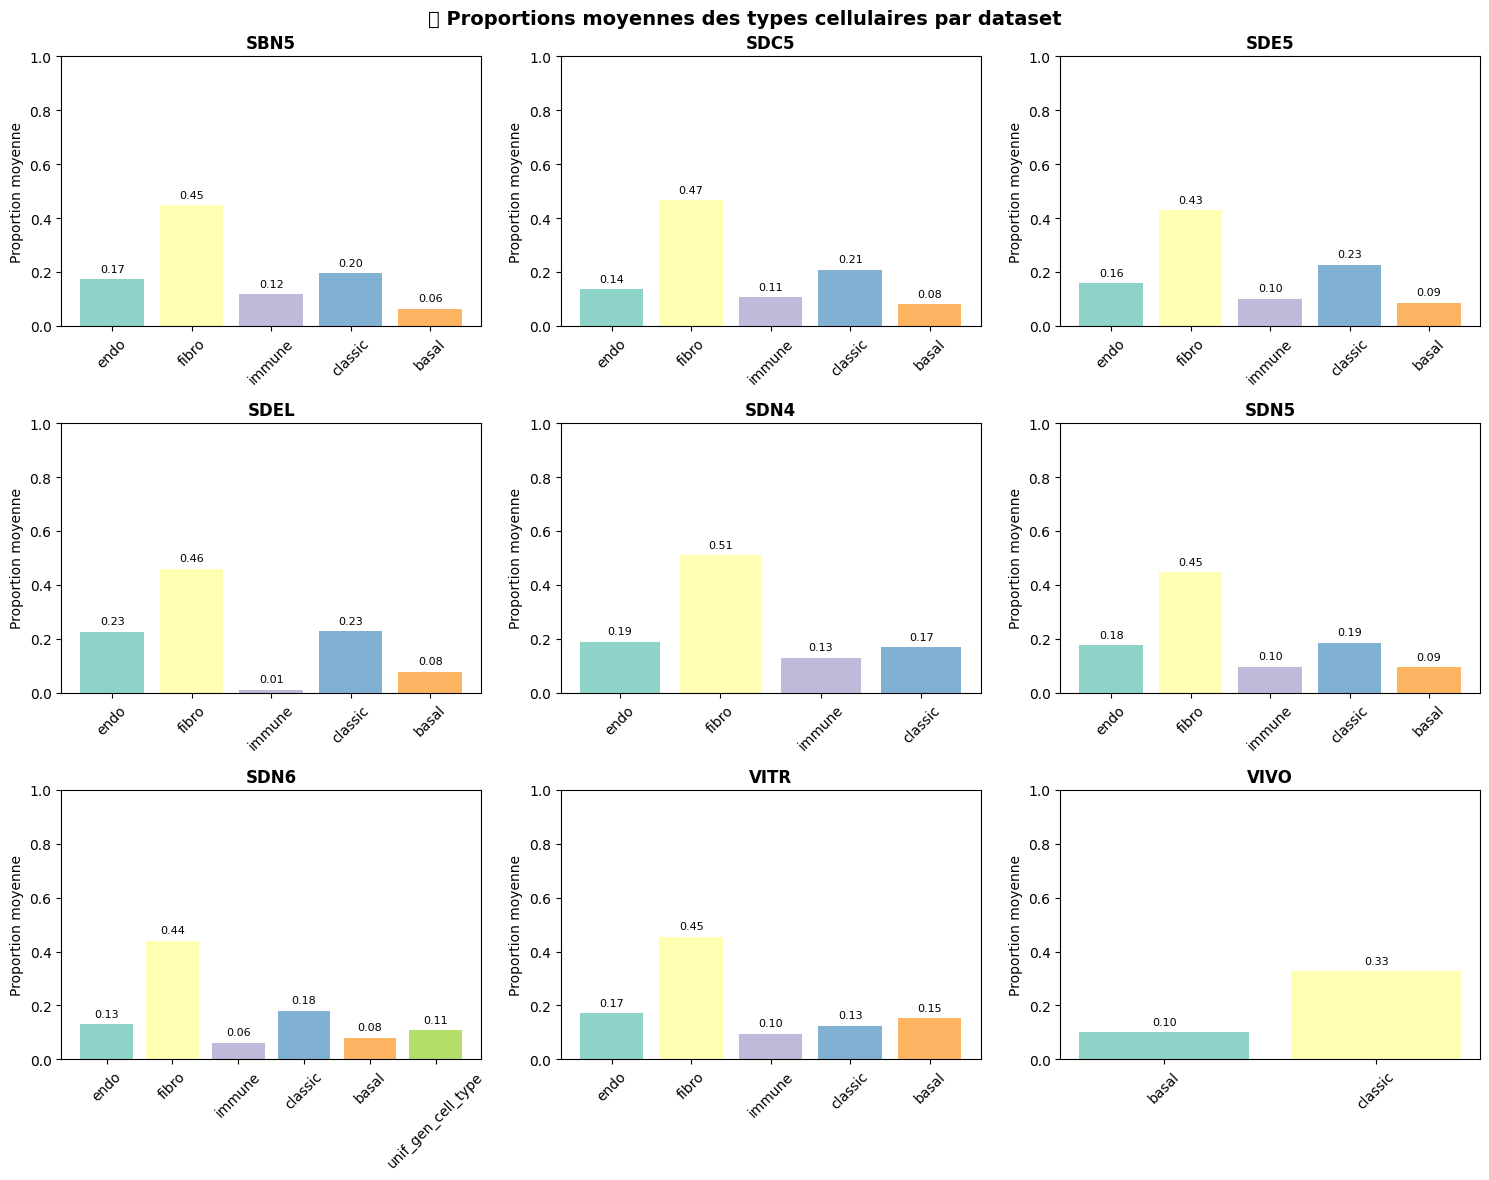

In [28]:
import matplotlib.pyplot as plt

# Visualiser les proportions moyennes par dataset
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

colors = plt.cm.Set3(np.linspace(0, 1, 10))

for idx, (ds, gt_df_temp) in enumerate(all_gt.items()):
    ax = axes[idx]
    means = gt_df_temp.mean()
    bars = ax.bar(means.index, means.values, color=colors[:len(means)])
    ax.set_title(f'{ds}', fontsize=12, fontweight='bold')
    ax.set_ylabel('Proportion moyenne')
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=45)
    
    # Ajouter les valeurs sur les barres
    for bar, val in zip(bars, means.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, 
                f'{val:.2f}', ha='center', va='bottom', fontsize=8)

plt.suptitle('📊 Proportions moyennes des types cellulaires par dataset', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 6.5 Statistiques globales sur les données RNA

In [29]:
# Analyser les statistiques des données RNA pour chaque dataset
print("📈 STATISTIQUES DES DONNÉES D'EXPRESSION RNA")
print("=" * 70)

stats_data = []

for ds in datasets:
    mix_path = f"{DATA_PATH}mixes_{ds}.h5"
    
    try:
        # Utiliser notre fonction robuste
        mix_df_temp = load_mix_rna(mix_path)
        data = mix_df_temp.values
        
        stats_data.append({
            'Dataset': ds,
            'Min': data.min(),
            'Max': data.max(),
            'Moyenne': data.mean(),
            'Médiane': np.median(data),
            'Std': data.std(),
            '% zéros': (data == 0).sum() / data.size * 100
        })
        
    except Exception as e:
        print(f"⚠️ {ds}: Erreur - {e}")

stats_df = pd.DataFrame(stats_data)
print("\n📊 Tableau des statistiques:")
stats_df

📈 STATISTIQUES DES DONNÉES D'EXPRESSION RNA

📊 Tableau des statistiques:


,Dataset,Min,Max,Moyenne,Médiane,Std,% zéros
0,SBN5,0.000000e+00,2.328200e+04,47.007145,14.000000,214.508320,18.380479
1,SDC5,0.000000e+00,1.039460e+06,2370.874927,794.152839,9841.788894,0.128656
2,SDE5,2.556387e-08,1.152363e+06,2873.727741,897.038520,13714.821062,0.000000
3,SDEL,5.865691e-07,1.250296e+06,2818.886700,847.278838,14242.422339,0.000000
4,SDN4,0.000000e+00,1.210580e+06,2963.487929,901.043323,14777.574259,0.089682
5,SDN5,0.000000e+00,1.034001e+06,2829.037686,893.276539,13236.454114,0.049870
6,SDN6,0.000000e+00,1.020618e+06,2832.641754,875.187562,13213.396353,0.051546
7,VITR,0.000000e+00,7.092220e+05,2286.593299,741.945531,8789.676122,3.981644
8,VIVO,0.000000e+00,1.562248e+05,254.156976,84.155672,1300.032849,8.267329


### 6.6 Vérifier les gènes communs entre Mix et Référence

In [30]:
# Vérifier les gènes communs entre chaque mix et la référence
print("🧬 ANALYSE DES GÈNES COMMUNS (MIX vs RÉFÉRENCE)")
print("=" * 70)

# Charger les gènes de la référence
with h5py.File(DATA_PATH + "reference_pdac.h5", 'r') as f:
    ref_genes_set = set([x.decode('utf-8') for x in f['ref_bulkRNA/genes'][:]])

print(f"📊 Gènes dans la référence: {len(ref_genes_set)}")
print("-" * 50)

genes_comparison = []

for ds in datasets:
    mix_path = f"{DATA_PATH}mixes_{ds}.h5"
    
    try:
        with h5py.File(mix_path, 'r') as f:
            if 'mix_rna' in f:
                mix_genes_ds = set([x.decode('utf-8') for x in f['mix_rna/genes'][:]])
            else:
                first_key = list(f.keys())[0]
                mix_genes_ds = set([x.decode('utf-8') for x in f[f'{first_key}/genes'][:]])
        
        common = len(mix_genes_ds.intersection(ref_genes_set))
        only_mix = len(mix_genes_ds - ref_genes_set)
        only_ref = len(ref_genes_set - mix_genes_ds)
        
        genes_comparison.append({
            'Dataset': ds,
            'Gènes mix': len(mix_genes_ds),
            'Gènes communs': common,
            'Uniquement mix': only_mix,
            'Uniquement ref': only_ref,
            '% utilisables': common / len(mix_genes_ds) * 100
        })
        
        print(f"\n📁 {ds}:")
        print(f"   Gènes dans le mix: {len(mix_genes_ds)}")
        print(f"   Gènes communs avec ref: {common} ({common/len(mix_genes_ds)*100:.1f}%)")
        
    except Exception as e:
        print(f"⚠️ {ds}: Erreur - {e}")

genes_df = pd.DataFrame(genes_comparison)
print("\n" + "=" * 70)
print("📋 TABLEAU RÉCAPITULATIF DES GÈNES")
genes_df

🧬 ANALYSE DES GÈNES COMMUNS (MIX vs RÉFÉRENCE)
📊 Gènes dans la référence: 15908
--------------------------------------------------

📁 SBN5:
   Gènes dans le mix: 15908
   Gènes communs avec ref: 15908 (100.0%)

📁 SDC5:
   Gènes dans le mix: 15908
   Gènes communs avec ref: 15908 (100.0%)

📁 SDE5:
   Gènes dans le mix: 15908
   Gènes communs avec ref: 15908 (100.0%)

📁 SDEL:
   Gènes dans le mix: 15908
   Gènes communs avec ref: 15908 (100.0%)

📁 SDN4:
   Gènes dans le mix: 15908
   Gènes communs avec ref: 15908 (100.0%)

📁 SDN5:
   Gènes dans le mix: 15908
   Gènes communs avec ref: 15908 (100.0%)

📁 SDN6:
   Gènes dans le mix: 15908
   Gènes communs avec ref: 15908 (100.0%)

📁 VITR:
   Gènes dans le mix: 15908
   Gènes communs avec ref: 15908 (100.0%)

📁 VIVO:
   Gènes dans le mix: 15908
   Gènes communs avec ref: 15908 (100.0%)

📋 TABLEAU RÉCAPITULATIF DES GÈNES


,Dataset,Gènes mix,Gènes communs,Uniquement mix,Uniquement ref,% utilisables
0,SBN5,15908,15908,0,0,100.0
1,SDC5,15908,15908,0,0,100.0
2,SDE5,15908,15908,0,0,100.0
3,SDEL,15908,15908,0,0,100.0
4,SDN4,15908,15908,0,0,100.0
5,SDN5,15908,15908,0,0,100.0
6,SDN6,15908,15908,0,0,100.0
7,VITR,15908,15908,0,0,100.0
8,VIVO,15908,15908,0,0,100.0


## 7. 🔧 Normalisation des données

Avant d'appliquer un algorithme de déconvolution, il est essentiel de **normaliser** les données pour :
1. Rendre les datasets comparables entre eux
2. Réduire l'impact des gènes très exprimés
3. Stabiliser la variance

In [31]:
# Fonctions de normalisation

def log2_transform(df):
    """
    Transformation log2(x + 1)
    - Réduit l'impact des valeurs extrêmes
    - Stabilise la variance
    """
    return np.log2(df + 1)

def quantile_normalize(df):
    """
    Normalisation par quantile
    - Rend les distributions identiques entre échantillons
    """
    rank_mean = df.stack().groupby(df.rank(method='first').stack().astype(int)).mean()
    return df.rank(method='min').stack().astype(int).map(rank_mean).unstack()

def zscore_normalize(df, axis=0):
    """
    Normalisation Z-score par gène (axis=0) ou par échantillon (axis=1)
    - Centre et réduit les données
    """
    return (df - df.mean(axis=axis)) / df.std(axis=axis)

def scale_normalize(df):
    """
    Normalisation Min-Max [0, 1]
    """
    return (df - df.min()) / (df.max() - df.min())

print("✅ Fonctions de normalisation définies!")

✅ Fonctions de normalisation définies!


### 7.1 Appliquer la normalisation Log2

La transformation **log2(x + 1)** est la plus courante en transcriptomique car elle :
- Réduit l'écart entre gènes faiblement et fortement exprimés
- Rend la distribution plus symétrique (proche d'une normale)

In [32]:
# Charger et normaliser les données pour SDN5 (exemple)
mix_path = f"{DATA_PATH}mixes_SDN5.h5"
mix_df = load_mix_rna(mix_path)

# Appliquer la transformation log2
mix_log = log2_transform(mix_df)

# Charger et normaliser la référence
with h5py.File(DATA_PATH + "reference_pdac.h5", 'r') as f:
    ref_data = f['ref_bulkRNA/data'][:]
    ref_cell_types = [x.decode('utf-8') for x in f['ref_bulkRNA/cell_types'][:]]
    ref_genes = [x.decode('utf-8') for x in f['ref_bulkRNA/genes'][:]]

ref_df = pd.DataFrame(ref_data.T, index=ref_genes, columns=ref_cell_types)
ref_log = log2_transform(ref_df)

print("📊 Comparaison AVANT / APRÈS normalisation log2")
print("=" * 60)
print("\n🔹 MIX (SDN5) - Données brutes:")
print(f"   Min: {mix_df.values.min():.2f}, Max: {mix_df.values.max():.2f}, Moyenne: {mix_df.values.mean():.2f}")
print("\n🔹 MIX (SDN5) - Après log2:")
print(f"   Min: {mix_log.values.min():.2f}, Max: {mix_log.values.max():.2f}, Moyenne: {mix_log.values.mean():.2f}")
print("\n🔹 RÉFÉRENCE - Données brutes:")
print(f"   Min: {ref_df.values.min():.2f}, Max: {ref_df.values.max():.2f}, Moyenne: {ref_df.values.mean():.2f}")
print("\n🔹 RÉFÉRENCE - Après log2:")
print(f"   Min: {ref_log.values.min():.2f}, Max: {ref_log.values.max():.2f}, Moyenne: {ref_log.values.mean():.2f}")

📊 Comparaison AVANT / APRÈS normalisation log2

🔹 MIX (SDN5) - Données brutes:
   Min: 0.00, Max: 1034001.10, Moyenne: 2829.04

🔹 MIX (SDN5) - Après log2:
   Min: 0.00, Max: 19.98, Moyenne: 8.91

🔹 RÉFÉRENCE - Données brutes:
   Min: 0.00, Max: 70924.25, Moyenne: 49.89

🔹 RÉFÉRENCE - Après log2:
   Min: 0.00, Max: 16.11, Moyenne: 3.72


### 7.2 Visualiser l'effet de la normalisation

/var/folders/1x/bcx97cwn2l38q006s07v1kr00000gn/T/ipykernel_1215/2367286270.py:31: UserWarning: Glyph 128313 (\N{SMALL BLUE DIAMOND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/1x/bcx97cwn2l38q006s07v1kr00000gn/T/ipykernel_1215/2367286270.py:31: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/1x/bcx97cwn2l38q006s07v1kr00000gn/T/ipykernel_1215/2367286270.py:31: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/amine/Desktop/M1/M1env/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 128313 (\N{SMALL BLUE DIAMOND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/amine/Desktop/M1/M1env/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/

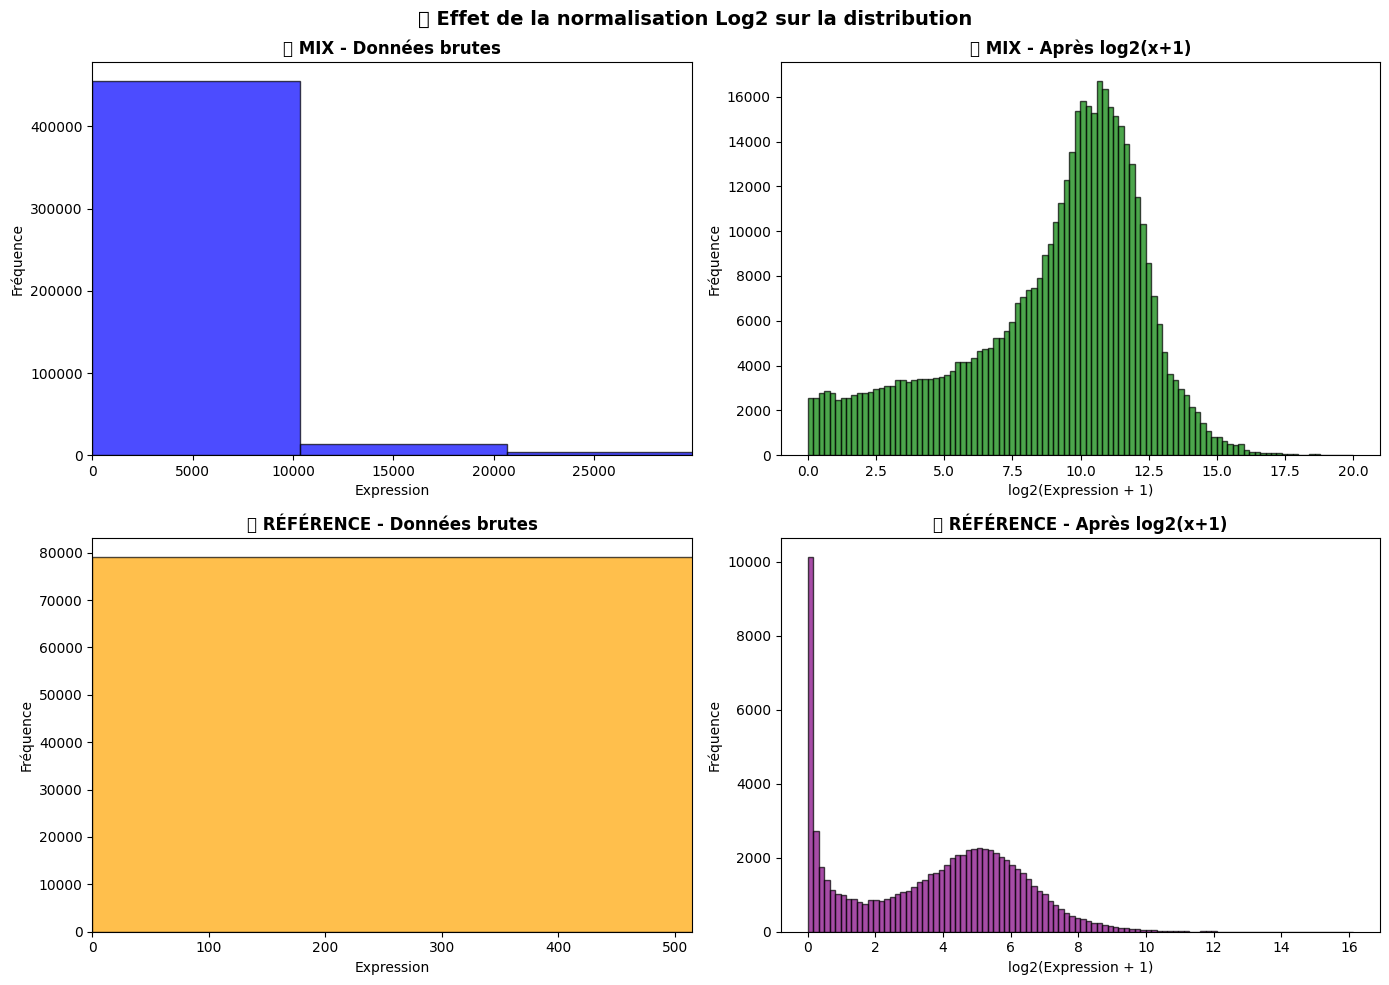


💡 Observation: La transformation log2 rend la distribution plus symétrique et comparable!


In [33]:
# Visualiser la distribution avant/après normalisation
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Distribution des données brutes (MIX)
axes[0, 0].hist(mix_df.values.flatten(), bins=100, alpha=0.7, color='blue', edgecolor='black')
axes[0, 0].set_title('🔹 MIX - Données brutes', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Expression')
axes[0, 0].set_ylabel('Fréquence')
axes[0, 0].set_xlim(0, np.percentile(mix_df.values, 99))  # Limiter pour mieux voir

# Distribution après log2 (MIX)
axes[0, 1].hist(mix_log.values.flatten(), bins=100, alpha=0.7, color='green', edgecolor='black')
axes[0, 1].set_title('✅ MIX - Après log2(x+1)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('log2(Expression + 1)')
axes[0, 1].set_ylabel('Fréquence')

# Distribution des données brutes (REF)
axes[1, 0].hist(ref_df.values.flatten(), bins=100, alpha=0.7, color='orange', edgecolor='black')
axes[1, 0].set_title('🔹 RÉFÉRENCE - Données brutes', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Expression')
axes[1, 0].set_ylabel('Fréquence')
axes[1, 0].set_xlim(0, np.percentile(ref_df.values, 99))

# Distribution après log2 (REF)
axes[1, 1].hist(ref_log.values.flatten(), bins=100, alpha=0.7, color='purple', edgecolor='black')
axes[1, 1].set_title('✅ RÉFÉRENCE - Après log2(x+1)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('log2(Expression + 1)')
axes[1, 1].set_ylabel('Fréquence')

plt.suptitle('📊 Effet de la normalisation Log2 sur la distribution', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n💡 Observation: La transformation log2 rend la distribution plus symétrique et comparable!")

### 7.3 Filtrer les gènes communs entre Mix et Référence

Pour la déconvolution, on ne peut utiliser que les gènes présents **à la fois** dans le mélange et dans la référence.

In [34]:
# Trouver les gènes communs
common_genes = mix_log.index.intersection(ref_log.index)

# Filtrer les données pour ne garder que les gènes communs
mix_filtered = mix_log.loc[common_genes]
ref_filtered = ref_log.loc[common_genes]

print("🧬 FILTRAGE DES GÈNES COMMUNS")
print("=" * 60)
print(f"   Gènes dans le mix: {len(mix_log)}")
print(f"   Gènes dans la référence: {len(ref_log)}")
print(f"   ✅ Gènes communs (utilisables): {len(common_genes)}")
print(f"\n📊 Dimensions finales:")
print(f"   Mix filtré: {mix_filtered.shape} (gènes × échantillons)")
print(f"   Ref filtrée: {ref_filtered.shape} (gènes × types cellulaires)")

🧬 FILTRAGE DES GÈNES COMMUNS
   Gènes dans le mix: 15908
   Gènes dans la référence: 15908
   ✅ Gènes communs (utilisables): 15908

📊 Dimensions finales:
   Mix filtré: (15908, 30) (gènes × échantillons)
   Ref filtrée: (15908, 5) (gènes × types cellulaires)


### 7.4 Fonction complète de prétraitement

Créons une fonction réutilisable pour normaliser n'importe quel dataset.

In [37]:
def preprocess_data(dataset_name, data_path=DATA_PATH, gt_path=GROUND_TRUTH_PATH):
    """
    Prétraitement complet d'un dataset pour la déconvolution.
    
    Étapes:
    1. Chargement des données (mix, ref, ground truth)
    2. Transformation log2
    3. Filtrage des gènes communs
    
    Retourne: mix_normalized, ref_normalized, ground_truth, common_genes
    """
    
    # 1. Charger les données
    mix_df = load_mix_rna(f"{data_path}mixes_{dataset_name}.h5")
    
    with h5py.File(f"{data_path}reference_pdac.h5", 'r') as f:
        ref_data = f['ref_bulkRNA/data'][:]
        ref_cell_types = [x.decode('utf-8') for x in f['ref_bulkRNA/cell_types'][:]]
        ref_genes = [x.decode('utf-8') for x in f['ref_bulkRNA/genes'][:]]
    ref_df = pd.DataFrame(ref_data.T, index=ref_genes, columns=ref_cell_types)
    
    with h5py.File(f"{gt_path}groundtruth_{dataset_name}.h5", 'r') as f:
        gt_data = f['groundtruth/data'][:]
        gt_types = [x.decode('utf-8') for x in f['groundtruth/genes'][:]]
    gt_df = pd.DataFrame(gt_data, columns=gt_types)
    gt_df.index = mix_df.columns  # Aligner les index
    
    # 2. Transformation log2
    mix_log = log2_transform(mix_df)
    ref_log = log2_transform(ref_df)
    
    # 3. Filtrer les gènes communs
    common_genes = mix_log.index.intersection(ref_log.index)
    mix_filtered = mix_log.loc[common_genes]
    ref_filtered = ref_log.loc[common_genes]
    
    return mix_filtered, ref_filtered, gt_df, list(common_genes)

# Tester la fonction sur SDN5
mix_norm, ref_norm, gt, genes = preprocess_data("SDN5")

print("✅ Prétraitement terminé pour SDN5!")
print(f"   Mix normalisé: {mix_norm.shape}")
print(f"   Ref normalisée: {ref_norm.shape}")
print(f"   Ground truth: {gt.shape}")
print(f"   Gènes utilisés: {len(genes)}")

✅ Prétraitement terminé pour SDN5!
   Mix normalisé: (15908, 30)
   Ref normalisée: (15908, 5)
   Ground truth: (30, 5)
   Gènes utilisés: 15908


### 7.5 Appliquer le prétraitement à tous les datasets

In [38]:
# Prétraiter tous les datasets et stocker les résultats
all_data = {}

print("🔄 PRÉTRAITEMENT DE TOUS LES DATASETS")
print("=" * 60)

for ds in datasets:
    try:
        mix_norm, ref_norm, gt, genes = preprocess_data(ds)
        all_data[ds] = {
            'mix': mix_norm,
            'ref': ref_norm,
            'gt': gt,
            'genes': genes
        }
        print(f"✅ {ds}: {mix_norm.shape[1]} samples, {len(genes)} gènes, {gt.shape[1]} types cellulaires")
    except Exception as e:
        print(f"⚠️ {ds}: Erreur - {e}")

print("\n" + "=" * 60)
print(f"📊 {len(all_data)} datasets prétraités avec succès!")

🔄 PRÉTRAITEMENT DE TOUS LES DATASETS
✅ SBN5: 30 samples, 15908 gènes, 5 types cellulaires
✅ SDC5: 30 samples, 15908 gènes, 5 types cellulaires
✅ SDE5: 30 samples, 15908 gènes, 5 types cellulaires
✅ SDEL: 30 samples, 15908 gènes, 5 types cellulaires
✅ SDN4: 30 samples, 15908 gènes, 4 types cellulaires
✅ SDN5: 30 samples, 15908 gènes, 5 types cellulaires
✅ SDN6: 30 samples, 15908 gènes, 6 types cellulaires
✅ VITR: 15 samples, 15908 gènes, 5 types cellulaires
✅ VIVO: 24 samples, 15908 gènes, 2 types cellulaires

📊 9 datasets prétraités avec succès!


## 8. ✅ Résumé du prétraitement

### Ce qui a été fait :
1. **Transformation log2(x+1)** : Stabilise la variance, réduit l'impact des valeurs extrêmes
2. **Filtrage des gènes communs** : Ne garde que les gènes présents dans mix ET référence
3. **Stockage dans `all_data`** : Dictionnaire contenant tous les datasets prétraités

### Données prêtes pour la déconvolution :
```python
all_data['SDN5']['mix']   # Mix normalisé (gènes × échantillons)
all_data['SDN5']['ref']   # Référence normalisée (gènes × types cellulaires)
all_data['SDN5']['gt']    # Ground truth (échantillons × types cellulaires)
```

### Prochaine étape :
Implémenter l'algorithme de **déconvolution** (NNLS, Ridge, etc.) pour estimer les proportions !

## 9. 🎯 Déconvolution avec NNLS

Maintenant que les données sont prétraitées, nous allons implémenter l'algorithme de **déconvolution** pour estimer les proportions de chaque type cellulaire.

### Méthode : NNLS (Non-Negative Least Squares)

Le problème mathématique est :
$$\text{Mix} = \text{Référence} \times \text{Proportions}$$

NNLS résout ce problème en garantissant que les **proportions sont positives** (≥ 0).

In [ ]:
from scipy.optimize import nnls

def deconvolve_nnls(mix_df, ref_df):
    """
    Déconvolution par NNLS (Non-Negative Least Squares).
    
    Args:
        mix_df: DataFrame (gènes × échantillons) - les mélanges à déconvoluer
        ref_df: DataFrame (gènes × types cellulaires) - la référence
    
    Returns:
        DataFrame (échantillons × types cellulaires) - les proportions estimées
    """
    # S'assurer que les gènes sont alignés
    common_genes = mix_df.index.intersection(ref_df.index)
    mix_aligned = mix_df.loc[common_genes]
    ref_aligned = ref_df.loc[common_genes]
    
    # Convertir en numpy arrays
    M = mix_aligned.values  # (n_genes, n_samples)
    R = ref_aligned.values  # (n_genes, n_cell_types)
    
    proportions = []
    
    # Pour chaque échantillon
    for i in range(M.shape[1]):
        sample = M[:, i]
        
        # Résoudre : R × props ≈ sample avec props ≥ 0
        props, _ = nnls(R, sample)
        
        # Normaliser pour que la somme = 1
        if props.sum() > 0:
            props = props / props.sum()
        
        proportions.append(props)
    
    # Créer le DataFrame résultat
    result = pd.DataFrame(
        proportions, 
        index=mix_df.columns,
        columns=ref_df.columns
    )
    
    return result

print("✅ Fonction de déconvolution NNLS définie!")

### 9.1 Tester la déconvolution sur SDN5

In [ ]:
# Tester sur SDN5
dataset = "SDN5"
mix_norm = all_data[dataset]['mix']
ref_norm = all_data[dataset]['ref']
gt = all_data[dataset]['gt']

# Déconvolution
pred = deconvolve_nnls(mix_norm, ref_norm)

print(f"🎯 DÉCONVOLUTION DE {dataset}")
print("=" * 60)
print(f"\n📊 Proportions PRÉDITES (premiers échantillons):")
print(pred.head())
print(f"\n📊 Proportions RÉELLES (Ground Truth):")
print(gt.head())

# Vérifier que les proportions somment à 1
print(f"\n✅ Vérification: les proportions prédites somment à 1?")
print(pred.sum(axis=1).head())

### 9.2 Évaluer la performance (métriques)

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.stats import pearsonr

def evaluate_deconvolution(pred, gt):
    """
    Évalue la qualité des proportions prédites vs ground truth.
    
    Métriques:
    - RMSE (Root Mean Square Error) : plus c'est bas, mieux c'est
    - MAE (Mean Absolute Error) : erreur moyenne
    - Pearson correlation : corrélation entre prédictions et réalité
    """
    # S'assurer que les colonnes sont alignées
    common_cols = pred.columns.intersection(gt.columns)
    pred_aligned = pred[common_cols]
    gt_aligned = gt[common_cols]
    
    # Aplatir pour les métriques globales
    pred_flat = pred_aligned.values.flatten()
    gt_flat = gt_aligned.values.flatten()
    
    rmse = np.sqrt(mean_squared_error(gt_flat, pred_flat))
    mae = mean_absolute_error(gt_flat, pred_flat)
    pearson, _ = pearsonr(pred_flat, gt_flat)
    
    # Métriques par type cellulaire
    metrics_per_type = {}
    for col in common_cols:
        r, _ = pearsonr(pred_aligned[col], gt_aligned[col])
        metrics_per_type[col] = {
            'RMSE': np.sqrt(mean_squared_error(gt_aligned[col], pred_aligned[col])),
            'Pearson': r
        }
    
    return {
        'RMSE': rmse,
        'MAE': mae,
        'Pearson': pearson,
        'per_type': metrics_per_type
    }

# Évaluer sur SDN5
metrics = evaluate_deconvolution(pred, gt)

print(f"📈 ÉVALUATION DE LA DÉCONVOLUTION ({dataset})")
print("=" * 60)
print(f"\n🎯 Métriques globales:")
print(f"   RMSE: {metrics['RMSE']:.4f} (↓ plus bas = meilleur)")
print(f"   MAE: {metrics['MAE']:.4f}")
print(f"   Pearson: {metrics['Pearson']:.4f} (↑ plus haut = meilleur)")

print(f"\n📊 Métriques par type cellulaire:")
for cell_type, m in metrics['per_type'].items():
    print(f"   {cell_type}: RMSE={m['RMSE']:.4f}, Pearson={m['Pearson']:.4f}")

### 9.3 Visualiser les résultats (Prédictions vs Ground Truth)

In [ ]:
# Visualisation: Prédictions vs Ground Truth par type cellulaire
common_cols = pred.columns.intersection(gt.columns)
n_types = len(common_cols)

fig, axes = plt.subplots(1, n_types, figsize=(4*n_types, 4))
if n_types == 1:
    axes = [axes]

for idx, cell_type in enumerate(common_cols):
    ax = axes[idx]
    
    # Scatter plot
    ax.scatter(gt[cell_type], pred[cell_type], alpha=0.6, edgecolor='black')
    
    # Ligne parfaite (y = x)
    lims = [0, max(gt[cell_type].max(), pred[cell_type].max()) + 0.05]
    ax.plot(lims, lims, 'r--', label='Parfait (y=x)')
    
    # Corrélation
    r = metrics['per_type'][cell_type]['Pearson']
    ax.set_title(f'{cell_type}\nPearson = {r:.3f}', fontsize=11, fontweight='bold')
    ax.set_xlabel('Ground Truth')
    ax.set_ylabel('Prédiction')
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.legend(loc='lower right', fontsize=8)

plt.suptitle(f'📊 Prédictions vs Ground Truth ({dataset})', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 9.4 Évaluer sur TOUS les datasets

In [ ]:
# Évaluer la déconvolution sur tous les datasets
print("🎯 ÉVALUATION SUR TOUS LES DATASETS")
print("=" * 70)

results_summary = []

for ds in all_data.keys():
    try:
        mix_norm = all_data[ds]['mix']
        ref_norm = all_data[ds]['ref']
        gt = all_data[ds]['gt']
        
        # Déconvolution
        pred = deconvolve_nnls(mix_norm, ref_norm)
        
        # Évaluation
        metrics = evaluate_deconvolution(pred, gt)
        
        results_summary.append({
            'Dataset': ds,
            'RMSE': metrics['RMSE'],
            'MAE': metrics['MAE'],
            'Pearson': metrics['Pearson'],
            'N_samples': len(pred),
            'N_types': len(gt.columns)
        })
        
        print(f"\n✅ {ds}: RMSE={metrics['RMSE']:.4f}, Pearson={metrics['Pearson']:.4f}")
        
    except Exception as e:
        print(f"\n⚠️ {ds}: Erreur - {e}")

# Tableau récapitulatif
results_df = pd.DataFrame(results_summary)
print("\n" + "=" * 70)
print("📊 TABLEAU RÉCAPITULATIF")
print("=" * 70)
results_df

## 10. 📋 Résumé et Prochaines Étapes

### ✅ Ce qui a été fait :
1. **Exploration des données** : structure, dimensions, types cellulaires
2. **Prétraitement** : log2 transform, filtrage des gènes communs
3. **Déconvolution NNLS** : estimation des proportions
4. **Évaluation** : RMSE, MAE, Pearson par dataset

### 🚀 Pistes d'amélioration :
- Tester d'autres méthodes : **Ridge**, **Lasso**, **ElasticNet**, **SVR**
- **Sélection de gènes marqueurs** pour réduire le bruit
- **Combiner RNA + méthylation** pour les datasets qui ont les deux
- **Utiliser les données single-cell** comme référence alternative

### 📝 Pour le submission_script.py :
Le code de déconvolution peut être adapté pour la soumission finale !